# Modelagem — Baseline

Regressão logística com a variável `vertical` agrupada em três faixas de risco (definidas no notebook 1) e codificada via WoE.

In [1]:
import sys

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

sys.path.append("../")

from utils.metrics import metrics_by_split
from utils.woe import WoEEncoder

import warnings

warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("../data/nuvem_fraud_dataset_pos_eda_v2.csv", sep=";", index_col=0)
df["created_at"] = pd.to_datetime(df["created_at"], utc=True)
df.head()

,created_at,txn_id,customer_id,amount,vertical,is_fraud,txns_prev_5min,txns_prev_15min,txns_prev_30min,txns_prev_1h,txns_prev_6h,txns_prev_24h,amount_to_customer_mean_ratio_30d,amount_to_customer_median_ratio_30d,amount_zscore_customer_30d,minutes_since_prev_txn,amt_sum_prev_24h,n_high_prev_24h,hour,age
0,2019-01-01 00:00:44+00:00,0,122,107.23,grocery_pos,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.0,0,0,40
1,2019-01-01 00:00:51+00:00,1,63,220.11,entertainment,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.0,0,0,56
2,2019-01-01 00:07:27+00:00,2,23,96.29,grocery_pos,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.0,0,0,73
3,2019-01-01 00:09:03+00:00,3,83,7.77,shopping_pos,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.0,0,0,51
4,2019-01-01 00:21:32+00:00,4,81,6.85,misc_pos,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.0,0,0,51


## Agrupamento da vertical

Mesma recategorização do notebook 1: alto, médio e baixo risco.

In [3]:
vertical_groups = {
    "vertical_high_risk": ["shopping_net", "grocery_pos", "misc_net"],
    "vertical_medium_risk": ["shopping_pos", "gas_transport", "travel", "misc_pos"],
    "vertical_low_risk": [
        "grocery_net", "entertainment", "personal_care", "kids_pets",
        "food_dining", "health_fitness", "home",
    ],
}

vertical_to_group = {
    vertical: group
    for group, verticals in vertical_groups.items()
    for vertical in verticals
}

df["vertical_group"] = df["vertical"].map(vertical_to_group)
assert df["vertical_group"].notna().all(), "Some verticals were not assigned to a group."

## Split temporal

Mesmo esquema testado no notebook 1: um mês de warmup (para as features de histórico), gaps de um mês entre as bases para simular a maturação do chargeback.

In [4]:
df["ym"] = df["created_at"].dt.strftime("%Y-%m")
conds = [
    df.ym < "2019-02",
    df.ym.between("2019-02", "2020-04"),
    df.ym == "2020-05",
    df.ym.between("2020-06", "2020-08"),
    df.ym == "2020-09",
    df.ym >= "2020-10",
]
df["split"] = np.select(
    conds,
    ["warmup", "train", "gap1", "valid", "gap2", "test"],
    default="unassigned",
)
df.groupby("split")["is_fraud"].agg(["size", "sum", "mean"])

,size,sum,mean
split,,,
gap1,13494,81,0.006003
gap2,12793,69,0.005394
test,51557,171,0.003317
train,203934,1159,0.005683
valid,48135,203,0.004217
warmup,9694,99,0.010213


In [5]:
target = "is_fraud"
features = ["vertical_group"]

train = df[df["split"] == "train"]
valid = df[df["split"] == "valid"]
test = df[df["split"] == "test"]

## WoE

O WoE é calculado **somente na base de treino** e reaplicado em validação e teste.

In [6]:
encoder = WoEEncoder(features, target=target).fit(train)

X_train = encoder.transform(train)
X_valid = encoder.transform(valid)
X_test = encoder.transform(test)

encoder.tables_["vertical_group"]

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
vertical_group,,,,,,,,
vertical_high_risk,45020,675,45695,0.224068,0.014772,2.599210,0.963833,0.347034
vertical_medium_risk,57022,278,57300,0.280973,0.004852,0.853682,-0.158530,0.006536
vertical_low_risk,100733,206,100939,0.494959,0.002041,0.359099,-1.026680,0.327337


In [7]:
encoder.iv()

vertical_group    0.680907
Name: IV, dtype: float64

## Regressão logística

In [8]:
model = LogisticRegression()
model.fit(X_train, train[target])

pd.Series(
    np.append(model.intercept_, model.coef_.ravel()),
    index=["intercept", *X_train.columns],
    name="coef",
)

intercept            -5.160607
vertical_group_woe    0.994343
Name: coef, dtype: float64

## Métricas

PR AUC (average precision), ROC AUC e KS em cada base.

In [9]:
baseline_metrics = metrics_by_split({
    "train": (train[target], model.predict_proba(X_train)[:, 1]),
    "valid": (valid[target], model.predict_proba(X_valid)[:, 1]),
    "test": (test[target], model.predict_proba(X_test)[:, 1]),
})

baseline_metrics

,n_txns,fraud_rate,pr_auc,roc_auc,ks
train,203934.0,0.005683,0.011833,0.714777,0.360379
valid,48135.0,0.004217,0.007781,0.681241,0.304716
test,51557.0,0.003317,0.006615,0.709953,0.329356


# Modelo 2 — vertical + valor alto

Adiciona a flag binária `high_amount` (amount > 200), avaliada no notebook 1, também codificada via WoE.

In [10]:
for data in (train, valid, test):
    data["high_amount"] = np.where(data["amount"] > 200, 1, 0)

features_2 = ["vertical_group", "high_amount"]

In [11]:
encoder_2 = WoEEncoder(features_2, target=target).fit(train)

X_train_2 = encoder_2.transform(train)
X_valid_2 = encoder_2.transform(valid)
X_test_2 = encoder_2.transform(test)

encoder_2.tables_["high_amount"]

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
high_amount,,,,,,,,
1,9286,876,10162,0.04983,0.086204,15.168098,2.803302,1.989802
0,193489,283,193772,0.95017,0.001460,0.256981,-1.362084,0.966817


In [12]:
encoder_2.iv()

high_amount       2.956619
vertical_group    0.680907
Name: IV, dtype: float64

In [13]:
model_2 = LogisticRegression()
model_2.fit(X_train_2, train[target])

pd.Series(
    np.append(model_2.intercept_, model_2.coef_.ravel()),
    index=["intercept", *X_train_2.columns],
    name="coef",
)

intercept            -5.128099
vertical_group_woe    0.478538
high_amount_woe       0.931447
Name: coef, dtype: float64

In [14]:
model_2_metrics = metrics_by_split({
    "train": (train[target], model_2.predict_proba(X_train_2)[:, 1]),
    "valid": (valid[target], model_2.predict_proba(X_valid_2)[:, 1]),
    "test": (test[target], model_2.predict_proba(X_test_2)[:, 1]),
})

model_2_metrics

,n_txns,fraud_rate,pr_auc,roc_auc,ks
train,203934.0,0.005683,0.099235,0.851052,0.710029
valid,48135.0,0.004217,0.068856,0.826021,0.680180
test,51557.0,0.003317,0.054497,0.823349,0.649882


## Comparação com o baseline

In [15]:
pd.concat(
    {"baseline": baseline_metrics, "vertical + high_amount": model_2_metrics},
    axis=1,
).swaplevel(axis=1).sort_index(axis=1)[["pr_auc", "roc_auc", "ks"]]

pr_auc                          roc_auc                         \
       baseline vertical + high_amount  baseline vertical + high_amount   
train  0.011833               0.099235  0.714777               0.851052   
valid  0.007781               0.068856  0.681241               0.826021   
test   0.006615               0.054497  0.709953               0.823349   

             ks                         
       baseline vertical + high_amount  
train  0.360379               0.710029  
valid  0.304716               0.680180  
test   0.329356               0.649882

# Modelo 3 — vertical + velocidade + comportamento de valor do cliente

Remove a flag `high_amount` e adiciona variáveis numéricas do cliente:

* `txns_prev_1h` e `txns_prev_24h`: número de transações do cliente na janela anterior
* `amount_to_customer_median_ratio_30d`: valor da transação / mediana do cliente nos 30 dias anteriores

Tratamento:
* a razão tem cauda longa → `log`; nulos (cliente sem histórico em 30 dias, ~0.05% da base, mas com taxa de fraude ~10%) recebem log(1) = 0 (neutro) e uma flag de ausência
* `vertical_group` segue codificada via WoE
* todas as variáveis são padronizadas para a regressão logística

In [16]:
ratio_col = "amount_to_customer_median_ratio_30d"
numeric_features = ["txns_prev_1h", "txns_prev_24h"]


def build_model_3_features(data: pd.DataFrame) -> pd.DataFrame:
    X = encoder.transform(data)  # WoE da vertical_group (ajustado no treino)
    X[numeric_features] = data[numeric_features]
    X["log_amount_median_ratio_30d"] = np.log(data[ratio_col]).fillna(0.0)
    X["amount_median_ratio_30d_missing"] = data[ratio_col].isna().astype(int)
    return X


X_train_3 = build_model_3_features(train)
X_valid_3 = build_model_3_features(valid)
X_test_3 = build_model_3_features(test)

X_train_3.describe().T

,count,mean,std,min,25%,50%,75%,max
vertical_group_woe,203934.0,-0.336743,0.789648,-1.026680,-1.02668,-0.15853,-0.158530,0.963833
txns_prev_1h,203934.0,0.189282,0.459810,0.000000,0.00000,0.00000,0.000000,6.000000
txns_prev_24h,203934.0,3.914933,3.069029,0.000000,2.00000,3.00000,5.000000,25.000000
log_amount_median_ratio_30d,203934.0,-0.283882,1.374116,-4.638277,-1.31853,0.00000,0.685682,6.661829
amount_median_ratio_30d_missing,203934.0,0.000059,0.007671,0.000000,0.00000,0.00000,0.000000,1.000000


In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model_3 = make_pipeline(StandardScaler(), LogisticRegression())
model_3.fit(X_train_3, train[target])

logreg_3 = model_3[-1]
pd.Series(
    np.append(logreg_3.intercept_, logreg_3.coef_.ravel()),
    index=["intercept", *X_train_3.columns],
    name="coef (padronizado)",
)

intercept                         -6.488548
vertical_group_woe                 0.604419
txns_prev_1h                       0.611293
txns_prev_24h                     -0.215858
log_amount_median_ratio_30d        1.325698
amount_median_ratio_30d_missing    0.099222
Name: coef (padronizado), dtype: float64

In [18]:
model_3_metrics = metrics_by_split({
    "train": (train[target], model_3.predict_proba(X_train_3)[:, 1]),
    "valid": (valid[target], model_3.predict_proba(X_valid_3)[:, 1]),
    "test": (test[target], model_3.predict_proba(X_test_3)[:, 1]),
})

model_3_metrics

,n_txns,fraud_rate,pr_auc,roc_auc,ks
train,203934.0,0.005683,0.253400,0.828305,0.622592
valid,48135.0,0.004217,0.215210,0.839700,0.671900
test,51557.0,0.003317,0.131061,0.795881,0.578082


## Comparação entre os modelos

In [19]:
pd.concat(
    {
        "1. vertical": baseline_metrics,
        "2. vertical + high_amount": model_2_metrics,
        "3. vertical + velocidade + ratio": model_3_metrics,
    },
    axis=1,
).swaplevel(axis=1).sort_index(axis=1)[["pr_auc", "roc_auc", "ks"]]

pr_auc                                                             \
      1. vertical 2. vertical + high_amount 3. vertical + velocidade + ratio   
train    0.011833                  0.099235                         0.253400   
valid    0.007781                  0.068856                         0.215210   
test     0.006615                  0.054497                         0.131061   

          roc_auc                                                             \
      1. vertical 2. vertical + high_amount 3. vertical + velocidade + ratio   
train    0.714777                  0.851052                         0.828305   
valid    0.681241                  0.826021                         0.839700   
test     0.709953                  0.823349                         0.795881   

               ks                                                             
      1. vertical 2. vertical + high_amount 3. vertical + velocidade + ratio  
train    0.360379                  0.710029                         0.622592  
valid    0.304716                  0.680180                         0.671900  
test     0.329356                  0.649882                         0.578082

# Modelo 4 — LightGBM

Mesmas variáveis do modelo 3 (sem o valor absoluto da transação). Como o modelo é baseado em árvores, as variáveis entram sem transformação:

* `vertical_group` como categórica nativa (sem WoE)
* `amount_to_customer_median_ratio_30d` em escala original; nulos são tratados nativamente pelo LightGBM
* `txns_prev_1h`, `txns_prev_24h`

Early stopping na base de validação (pela average precision), então as métricas de validação ficam levemente otimistas — **o teste é a referência**.

In [20]:
import lightgbm as lgb

features_4 = ["vertical_group", "txns_prev_1h", "txns_prev_24h", ratio_col]


def build_model_4_features(data: pd.DataFrame) -> pd.DataFrame:
    X = data[features_4].copy()
    X["vertical_group"] = pd.Categorical(
        X["vertical_group"], categories=list(vertical_groups)
    )
    return X


X_train_4 = build_model_4_features(train)
X_valid_4 = build_model_4_features(valid)
X_test_4 = build_model_4_features(test)

In [21]:
model_4 = lgb.LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=15,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    verbose=-1,
)

model_4.fit(
    X_train_4,
    train[target],
    eval_set=[(X_valid_4, valid[target])],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(100, verbose=False)],
)

print(f"Melhor iteração: {model_4.best_iteration_}")

Melhor iteração: 47


In [22]:
pd.Series(
    model_4.booster_.feature_importance(importance_type="gain"),
    index=features_4,
    name="gain",
).sort_values(ascending=False).pipe(lambda s: s / s.sum())

amount_to_customer_median_ratio_30d    0.686708
txns_prev_1h                           0.142904
vertical_group                         0.128112
txns_prev_24h                          0.042276
Name: gain, dtype: float64

In [23]:
model_4_metrics = metrics_by_split({
    "train": (train[target], model_4.predict_proba(X_train_4)[:, 1]),
    "valid": (valid[target], model_4.predict_proba(X_valid_4)[:, 1]),
    "test": (test[target], model_4.predict_proba(X_test_4)[:, 1]),
})

model_4_metrics

,n_txns,fraud_rate,pr_auc,roc_auc,ks
train,203934.0,0.005683,0.338725,0.913756,0.676162
valid,48135.0,0.004217,0.304985,0.919610,0.693308
test,51557.0,0.003317,0.142574,0.884758,0.621538


## Comparação entre os modelos

In [24]:
pd.concat(
    {
        "1. vertical": baseline_metrics,
        "2. vertical + high_amount": model_2_metrics,
        "3. vertical + velocidade + ratio": model_3_metrics,
        "4. lightgbm": model_4_metrics,
    },
    axis=1,
).swaplevel(axis=1).sort_index(axis=1)[["pr_auc", "roc_auc", "ks"]]

pr_auc                                                             \
      1. vertical 2. vertical + high_amount 3. vertical + velocidade + ratio   
train    0.011833                  0.099235                         0.253400   
valid    0.007781                  0.068856                         0.215210   
test     0.006615                  0.054497                         0.131061   

                      roc_auc                            \
      4. lightgbm 1. vertical 2. vertical + high_amount   
train    0.338725    0.714777                  0.851052   
valid    0.304985    0.681241                  0.826021   
test     0.142574    0.709953                  0.823349   

                                                            ks  \
      3. vertical + velocidade + ratio 4. lightgbm 1. vertical   
train                         0.828305    0.913756    0.360379   
valid                         0.839700    0.919610    0.304716   
test                          0.795881    0.884758    0.329356   

                                                                              
      2. vertical + high_amount 3. vertical + velocidade + ratio 4. lightgbm  
train                  0.710029                         0.622592    0.676162  
valid                  0.680180                         0.671900    0.693308  
test                   0.649882                         0.578082    0.621538

# Modelo 5 — LightGBM + horário

Mesmas variáveis do modelo 4, acrescidas das variáveis de horário avaliadas no notebook 1 (taxa de fraude ~20x maior de madrugada):

* `night`: flag para transações entre 22h e 03h (UTC)
* `hour`: hora da transação (UTC), para o modelo capturar o padrão por hora além da flag

Mesmos hiperparâmetros e mesmo early stopping na validação do modelo 4.

In [25]:
for data in (train, valid, test):
    data["hour"] = data["created_at"].dt.hour
    data["night"] = data["hour"].isin([22, 23, 0, 1, 2, 3]).astype(int)

train.groupby("night")[target].agg(["size", "mean"])

,size,mean
night,,
0,156167,0.001005
1,47767,0.020977


In [26]:
features_5 = [*features_4, "night", "hour"]


def build_model_5_features(data: pd.DataFrame) -> pd.DataFrame:
    X = data[features_5].copy()
    X["vertical_group"] = pd.Categorical(
        X["vertical_group"], categories=list(vertical_groups)
    )
    return X


X_train_5 = build_model_5_features(train)
X_valid_5 = build_model_5_features(valid)
X_test_5 = build_model_5_features(test)

In [27]:
model_5 = lgb.LGBMClassifier(**model_4.get_params())

model_5.fit(
    X_train_5,
    train[target],
    eval_set=[(X_valid_5, valid[target])],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(100, verbose=False)],
)

print(f"Melhor iteração: {model_5.best_iteration_}")

Melhor iteração: 249


In [28]:
pd.Series(
    model_5.booster_.feature_importance(importance_type="gain"),
    index=features_5,
    name="gain",
).sort_values(ascending=False).pipe(lambda s: s / s.sum())

amount_to_customer_median_ratio_30d    0.512743
night                                  0.235871
txns_prev_1h                           0.087246
vertical_group                         0.073686
hour                                   0.064059
txns_prev_24h                          0.026395
Name: gain, dtype: float64

In [29]:
model_5_metrics = metrics_by_split({
    "train": (train[target], model_5.predict_proba(X_train_5)[:, 1]),
    "valid": (valid[target], model_5.predict_proba(X_valid_5)[:, 1]),
    "test": (test[target], model_5.predict_proba(X_test_5)[:, 1]),
})

model_5_metrics

,n_txns,fraud_rate,pr_auc,roc_auc,ks
train,203934.0,0.005683,0.546649,0.975500,0.843368
valid,48135.0,0.004217,0.491247,0.967644,0.833799
test,51557.0,0.003317,0.348416,0.951963,0.800295


## Comparação entre os modelos

In [30]:
pd.concat(
    {
        "1. vertical": baseline_metrics,
        "2. vertical + high_amount": model_2_metrics,
        "3. vertical + velocidade + ratio": model_3_metrics,
        "4. lightgbm": model_4_metrics,
        "5. lightgbm + horário": model_5_metrics,
    },
    axis=1,
).swaplevel(axis=1).sort_index(axis=1)[["pr_auc", "roc_auc", "ks"]]

pr_auc                                                             \
      1. vertical 2. vertical + high_amount 3. vertical + velocidade + ratio   
train    0.011833                  0.099235                         0.253400   
valid    0.007781                  0.068856                         0.215210   
test     0.006615                  0.054497                         0.131061   

                                            roc_auc                            \
      4. lightgbm 5. lightgbm + horário 1. vertical 2. vertical + high_amount   
train    0.338725              0.546649    0.714777                  0.851052   
valid    0.304985              0.491247    0.681241                  0.826021   
test     0.142574              0.348416    0.709953                  0.823349   

                                                                          \
      3. vertical + velocidade + ratio 4. lightgbm 5. lightgbm + horário   
train                         0.828305    0.913756              0.975500   
valid                         0.839700    0.919610              0.967644   
test                          0.795881    0.884758              0.951963   

               ks                                                             \
      1. vertical 2. vertical + high_amount 3. vertical + velocidade + ratio   
train    0.360379                  0.710029                         0.622592   
valid    0.304716                  0.680180                         0.671900   
test     0.329356                  0.649882                         0.578082   

                                         
      4. lightgbm 5. lightgbm + horário  
train    0.676162              0.843368  
valid    0.693308              0.833799  
test     0.621538              0.800295

O modelo 5 domina todos os anteriores em todas as bases e métricas — no teste, a PR AUC passa de 0,14 (modelo 4) para ~0,35 e o KS de 0,62 para ~0,80.


# Modelo 6 — LightGBM + horário + valor

Modelo 5 acrescido de variáveis de valor:

* `amount`: valor da transação (os modelos 3–5 só usavam a razão para a mediana do cliente)
* `amt_sum_prev_24h`: soma do valor transacionado pelo cliente nas 24h anteriores
* `n_high_prev_24h`: número de transações de valor alto (> R$ 200) do cliente nas 24h anteriores

As duas variáveis de 24h vêm do notebook 1 e usam janela `[t - 24h, t)` — só transações estritamente anteriores, sem vazamento da transação corrente.

Também foram testadas `amount_zscore_customer_30d`, `amount_to_customer_mean_ratio_30d` e a flag `high_amount`: não melhoraram a PR AUC de validação em relação a este conjunto.

In [31]:
features_6 = [*features_5, "amount", "amt_sum_prev_24h", "n_high_prev_24h"]


def build_model_6_features(data: pd.DataFrame) -> pd.DataFrame:
    X = data[features_6].copy()
    X["vertical_group"] = pd.Categorical(
        X["vertical_group"], categories=list(vertical_groups)
    )
    return X


X_train_6 = build_model_6_features(train)
X_valid_6 = build_model_6_features(valid)
X_test_6 = build_model_6_features(test)

In [32]:
model_6 = lgb.LGBMClassifier(**model_4.get_params())

model_6.fit(
    X_train_6,
    train[target],
    eval_set=[(X_valid_6, valid[target])],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(100, verbose=False)],
)

print(f"Melhor iteração: {model_6.best_iteration_}")

Melhor iteração: 609


In [33]:
pd.Series(
    model_6.booster_.feature_importance(importance_type="gain"),
    index=features_6,
    name="gain",
).sort_values(ascending=False).pipe(lambda s: s / s.sum())

amount                                 0.343302
n_high_prev_24h                        0.324168
amt_sum_prev_24h                       0.080603
night                                  0.065487
txns_prev_24h                          0.058863
amount_to_customer_median_ratio_30d    0.055174
hour                                   0.034432
vertical_group                         0.031249
txns_prev_1h                           0.006722
Name: gain, dtype: float64

In [34]:
model_6_metrics = metrics_by_split({
    "train": (train[target], model_6.predict_proba(X_train_6)[:, 1]),
    "valid": (valid[target], model_6.predict_proba(X_valid_6)[:, 1]),
    "test": (test[target], model_6.predict_proba(X_test_6)[:, 1]),
})

model_6_metrics

,n_txns,fraud_rate,pr_auc,roc_auc,ks
train,203934.0,0.005683,0.971216,0.999690,0.985286
valid,48135.0,0.004217,0.872371,0.998031,0.964753
test,51557.0,0.003317,0.832804,0.988921,0.914139


## Comparação entre os modelos

In [35]:
pd.concat(
    {
        "1. vertical": baseline_metrics,
        "2. vertical + high_amount": model_2_metrics,
        "3. vertical + velocidade + ratio": model_3_metrics,
        "4. lightgbm": model_4_metrics,
        "5. lightgbm + horário": model_5_metrics,
        "6. lightgbm + horário + valor": model_6_metrics,
    },
    axis=1,
).swaplevel(axis=1).sort_index(axis=1)[["pr_auc", "roc_auc", "ks"]]

pr_auc                                                             \
      1. vertical 2. vertical + high_amount 3. vertical + velocidade + ratio   
train    0.011833                  0.099235                         0.253400   
valid    0.007781                  0.068856                         0.215210   
test     0.006615                  0.054497                         0.131061   

                                                                       \
      4. lightgbm 5. lightgbm + horário 6. lightgbm + horário + valor   
train    0.338725              0.546649                      0.971216   
valid    0.304985              0.491247                      0.872371   
test     0.142574              0.348416                      0.832804   

          roc_auc                                                             \
      1. vertical 2. vertical + high_amount 3. vertical + velocidade + ratio   
train    0.714777                  0.851052                         0.828305   
valid    0.681241                  0.826021                         0.839700   
test     0.709953                  0.823349                         0.795881   

                                                                       \
      4. lightgbm 5. lightgbm + horário 6. lightgbm + horário + valor   
train    0.913756              0.975500                      0.999690   
valid    0.919610              0.967644                      0.998031   
test     0.884758              0.951963                      0.988921   

               ks                                                             \
      1. vertical 2. vertical + high_amount 3. vertical + velocidade + ratio   
train    0.360379                  0.710029                         0.622592   
valid    0.304716                  0.680180                         0.671900   
test     0.329356                  0.649882                         0.578082   

                                                                       
      4. lightgbm 5. lightgbm + horário 6. lightgbm + horário + valor  
train    0.676162              0.843368                      0.985286  
valid    0.693308              0.833799                      0.964753  
test     0.621538              0.800295                      0.914139

O modelo 6 é o melhor em todas as bases e métricas: no teste, a PR AUC sobe de ~0,35 (modelo 5) para ~0,83 e o KS de 0,80 para ~0,91. O ganho vem principalmente das variáveis de 24h — fraudes chegam em rajadas de compras de valor alto do mesmo cliente.

# Modelo 6b — ajuste de hiperparâmetros (Optuna)

O modelo 6 usa os hiperparâmetros do modelo 4 (~600 árvores de até 15 folhas) e tem gap relevante entre treino e validação. O objetivo é **reduzir a complexidade** sem perder desempenho.

Busca multiobjetivo com Optuna (TPE):
* **maximizar** a PR AUC de validação
* **minimizar** o número total de folhas do ensemble (árvores × folhas), medida direta de complexidade

Espaço de busca restrito a árvores rasas (`max_depth` ≤ 4, `num_leaves` ≤ 15) e com mais regularização (`min_child_samples`, `reg_lambda`, amostragem de linhas e colunas). Mesmo early stopping do modelo 6.

Escolha final: entre os trials da fronteira de Pareto, o **mais simples** cuja PR AUC de validação fica a no máximo 0,01 da melhor.

In [36]:
import matplotlib.pyplot as plt
import optuna
from sklearn.metrics import average_precision_score

optuna.logging.set_verbosity(optuna.logging.WARNING)


def total_leaves(model: lgb.LGBMClassifier) -> int:
    trees = model.booster_.dump_model()["tree_info"][: model.best_iteration_]
    return sum(tree["num_leaves"] for tree in trees)


def fit_model_6(params: dict) -> lgb.LGBMClassifier:
    model = lgb.LGBMClassifier(**{**model_4.get_params(), **params})
    return model.fit(
        X_train_6,
        train[target],
        eval_set=[(X_valid_6, valid[target])],
        eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )


def objective(trial: optuna.Trial) -> tuple[float, int]:
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.03, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 2, 15),
        "max_depth": trial.suggest_int("max_depth", 1, 4),
        "min_child_samples": trial.suggest_int("min_child_samples", 50, 2000, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 100, log=True),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
    }
    model = fit_model_6(params)
    trial.set_user_attr("best_iteration", model.best_iteration_)
    pr_auc = average_precision_score(valid[target], model.predict_proba(X_valid_6)[:, 1])
    return pr_auc, total_leaves(model)

In [37]:
study = optuna.create_study(
    directions=["maximize", "minimize"],
    sampler=optuna.samplers.TPESampler(seed=42),
)
study.optimize(objective, n_trials=60)

pareto = (
    pd.DataFrame(
        [{"trial": t.number, "valid_pr_auc": t.values[0], "total_leaves": t.values[1],
          "best_iteration": t.user_attrs["best_iteration"], **t.params}
         for t in study.best_trials]
    )
    .sort_values("total_leaves")
    .reset_index(drop=True)
)
pareto

,trial,valid_pr_auc,total_leaves,best_iteration,learning_rate,num_leaves,max_depth,min_child_samples,reg_lambda,colsample_bytree,subsample
0,32,0.809608,980.0,490,0.173455,7,1,989,0.941987,0.799973,0.602834
1,13,0.810365,1018.0,509,0.199733,9,1,1158,4.687063,0.712119,0.671400
2,23,0.810615,1090.0,545,0.179330,10,1,1986,5.721127,0.706695,0.656941
3,53,0.866403,1223.0,320,0.187402,8,2,1105,1.151127,0.849376,0.683142
4,33,0.867267,1553.0,404,0.165941,6,2,995,0.864081,0.801753,0.602455
5,21,0.868805,1845.0,483,0.171745,8,2,1248,1.819953,0.709133,0.689333
6,31,0.869585,2377.0,622,0.173953,8,2,1400,2.215819,0.678880,0.633279
7,22,0.870289,2564.0,405,0.117352,7,3,1127,0.962614,0.804081,0.635125
8,15,0.871801,2683.0,267,0.101824,12,4,984,0.010745,0.859100,0.509387
9,59,0.871835,3315.0,480,0.126030,7,4,1435,3.941158,0.897367,0.763115


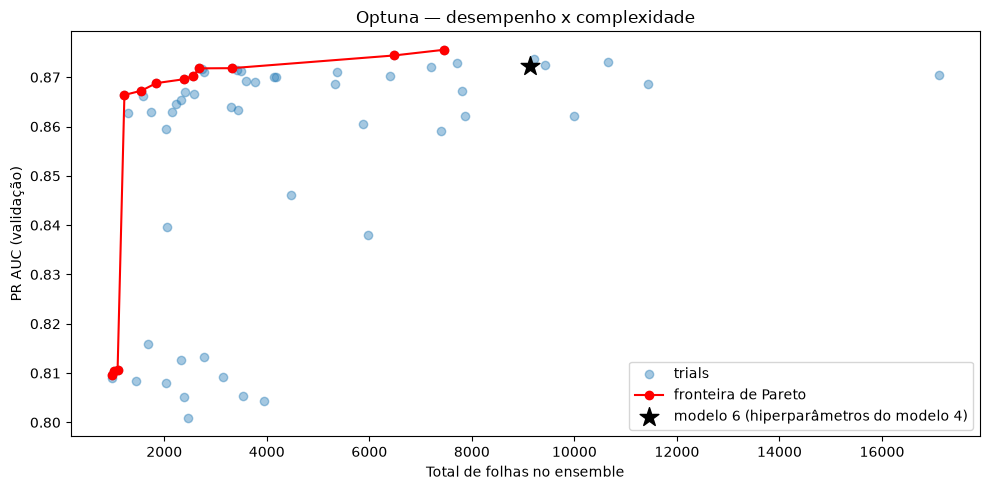

In [38]:
fig, ax = plt.subplots(figsize=(10, 5))
all_trials = np.array([t.values for t in study.trials if t.values is not None])
ax.scatter(all_trials[:, 1], all_trials[:, 0], alpha=0.4, label="trials")
ax.plot(pareto["total_leaves"], pareto["valid_pr_auc"], "o-", color="red", label="fronteira de Pareto")
ax.scatter(total_leaves(model_6), average_precision_score(valid[target], model_6.predict_proba(X_valid_6)[:, 1]),
           marker="*", s=200, color="black", label="modelo 6 (hiperparâmetros do modelo 4)", zorder=3)
ax.set_xlabel("Total de folhas no ensemble")
ax.set_ylabel("PR AUC (validação)")
ax.set_title("Optuna — desempenho x complexidade")
ax.legend()
plt.tight_layout()
plt.show()

In [39]:
tolerance = 0.01
chosen = pareto[pareto["valid_pr_auc"] >= pareto["valid_pr_auc"].max() - tolerance].iloc[0]
best_params_6b = study.trials[int(chosen["trial"])].params

model_6b = fit_model_6(best_params_6b)

pd.DataFrame(
    {
        "6. lightgbm + horário + valor": {
            "num_leaves": model_6.num_leaves, "max_depth": model_6.max_depth,
            "min_child_samples": model_6.min_child_samples, "n_trees": model_6.best_iteration_,
            "total_leaves": total_leaves(model_6),
        },
        "6b. tunado (Optuna)": {
            "num_leaves": model_6b.num_leaves, "max_depth": model_6b.max_depth,
            "min_child_samples": model_6b.min_child_samples, "n_trees": model_6b.best_iteration_,
            "total_leaves": total_leaves(model_6b),
        },
    }
)

,6. lightgbm + horário + valor,6b. tunado (Optuna)
num_leaves,15,8
max_depth,-1,2
min_child_samples,100,1105
n_trees,609,320
total_leaves,9135,1223


In [40]:
model_6b_metrics = metrics_by_split({
    "train": (train[target], model_6b.predict_proba(X_train_6)[:, 1]),
    "valid": (valid[target], model_6b.predict_proba(X_valid_6)[:, 1]),
    "test": (test[target], model_6b.predict_proba(X_test_6)[:, 1]),
})

pd.concat(
    {"6. lightgbm + horário + valor": model_6_metrics, "6b. tunado (Optuna)": model_6b_metrics},
    axis=1,
).swaplevel(axis=1).sort_index(axis=1)[["pr_auc", "roc_auc", "ks"]]

pr_auc                      \
      6. lightgbm + horário + valor 6b. tunado (Optuna)   
train                      0.971216            0.930234   
valid                      0.872371            0.866403   
test                       0.832804            0.813907   

                            roc_auc                      \
      6. lightgbm + horário + valor 6b. tunado (Optuna)   
train                      0.999690            0.998528   
valid                      0.998031            0.997438   
test                       0.988921            0.986720   

                                 ks                      
      6. lightgbm + horário + valor 6b. tunado (Optuna)  
train                      0.985286            0.967292  
valid                      0.964753            0.963775  
test                       0.914139            0.904370

O modelo 6b tem **~7,5x menos folhas** (1.223 vs 9.135: 320 árvores de profundidade 2 com folhas de ≥ 1.105 transações, contra 609 árvores sem limite de profundidade) e perde pouco desempenho: PR AUC de teste 0,81 vs 0,83, KS 0,90 vs 0,91. O gap treino–validação de PR AUC cai de ~0,10 para ~0,06.

A fronteira de Pareto mostra que árvores de profundidade 1 (sem interações) ficam ~0,06 abaixo em PR AUC — as interações de 2ª ordem são necessárias. Acima de ~1.200 folhas o ganho em validação é marginal.

Por ser mais simples e com desempenho equivalente, a decisão de bloqueio passa a usar o **modelo 6b**.


# Otimização do threshold — Modelo 6b

Estrutura de P&L da decisão (bloquear se score ≥ threshold):

| Resultado | Custo |
|---|---|
| FN — fraude aprovada | 100% do amount + R$ 15,00 de chargeback |
| FP — legítima bloqueada | 10% do amount (margem perdida) + custo de análise manual |
| TP — fraude bloqueada | 0 |
| TN — legítima aprovada | 0 (receita gerada) |

O custo de análise manual não é informado no case: assume-se **R$ 5,00** e avalia-se a sensibilidade a esse valor.

O threshold é escolhido na **validação** e avaliado no **teste** (fora da amostra).

In [41]:
from utils.pnl import decision_pnl, optimal_threshold, threshold_cost_curve

pnl_params = {"chargeback_fee": 15.0, "margin": 0.10, "review_cost": 5.0}

# Modelos 4, 5 e 6: thresholds anteriores, mantidos como referência
score_valid_4 = model_4.predict_proba(X_valid_4)[:, 1]
score_test_4 = model_4.predict_proba(X_test_4)[:, 1]
best_threshold_4 = optimal_threshold(
    threshold_cost_curve(valid[target], score_valid_4, valid["amount"], **pnl_params)
)

score_valid_5 = model_5.predict_proba(X_valid_5)[:, 1]
score_test_5 = model_5.predict_proba(X_test_5)[:, 1]
best_threshold_5 = optimal_threshold(
    threshold_cost_curve(valid[target], score_valid_5, valid["amount"], **pnl_params)
)

score_valid_6 = model_6.predict_proba(X_valid_6)[:, 1]
score_test_6 = model_6.predict_proba(X_test_6)[:, 1]
best_threshold_6 = optimal_threshold(
    threshold_cost_curve(valid[target], score_valid_6, valid["amount"], **pnl_params)
)

score_valid_6b = model_6b.predict_proba(X_valid_6)[:, 1]
score_test_6b = model_6b.predict_proba(X_test_6)[:, 1]

curve_valid = threshold_cost_curve(valid[target], score_valid_6b, valid["amount"], **pnl_params)
best_threshold = optimal_threshold(curve_valid)

print(f"Threshold ótimo (validação) — modelo 4: {best_threshold_4:.4f}")
print(f"Threshold ótimo (validação) — modelo 5: {best_threshold_5:.4f}")
print(f"Threshold ótimo (validação) — modelo 6: {best_threshold_6:.4f}")
print(f"Threshold ótimo (validação) — modelo 6b: {best_threshold:.4f}")
curve_valid.loc[curve_valid["total_cost"].idxmin()]

Threshold ótimo (validação) — modelo 4: 0.0992
Threshold ótimo (validação) — modelo 5: 0.1965
Threshold ótimo (validação) — modelo 6: 0.0593
Threshold ótimo (validação) — modelo 6b: 0.1306


threshold                     0.130643
n_blocked                   263.000000
block_rate                    0.005464
recall                        0.857143
precision                     0.661597
total_cost                11201.007000
savings_vs_approve_all    97352.563000
Name: 262, dtype: float64

Curva de custo na validação, em torno do ótimo:

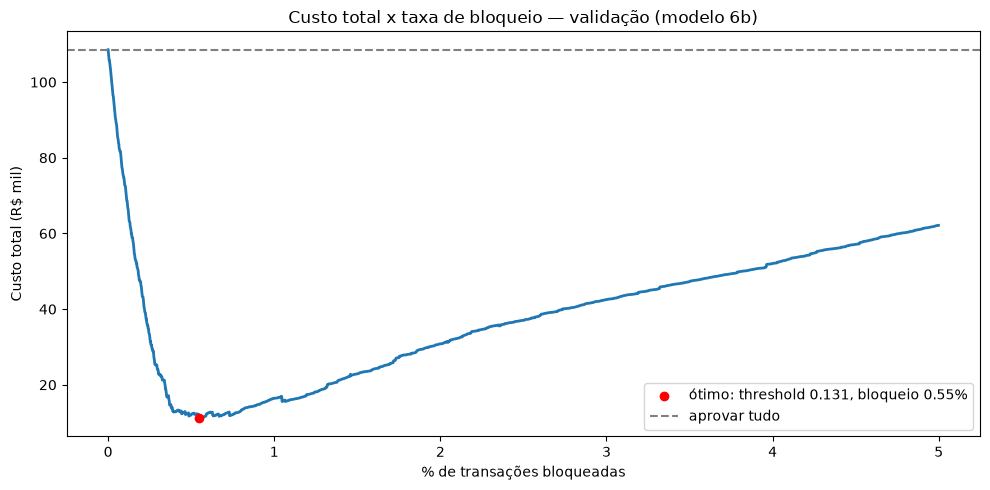

In [42]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
plot_curve = curve_valid[curve_valid["block_rate"] <= 0.05]
ax.plot(plot_curve["block_rate"] * 100, plot_curve["total_cost"] / 1e3, linewidth=2)
best_row = curve_valid.loc[curve_valid["total_cost"].idxmin()]
ax.scatter(best_row["block_rate"] * 100, best_row["total_cost"] / 1e3, color="red", zorder=3,
           label=f"ótimo: threshold {best_threshold:.3f}, bloqueio {best_row['block_rate']:.2%}")
ax.axhline(curve_valid["total_cost"].iloc[0] / 1e3, color="gray", linestyle="--", label="aprovar tudo")
ax.set_xlabel("% de transações bloqueadas")
ax.set_ylabel("Custo total (R$ mil)")
ax.set_title("Custo total x taxa de bloqueio — validação (modelo 6b)")
ax.legend()
plt.tight_layout()
plt.show()

## Avaliação no teste

Comparação com:
* **aprovar tudo** (sem modelo)
* **regra de valor**: bloquear amount > 200 (política simples avaliada no notebook 1)

In [43]:
policies = {
    "aprovar tudo": np.zeros(len(test), dtype=bool),
    "regra amount > 200": test["amount"].gt(200).to_numpy(),
    f"modelo 4 (threshold {best_threshold_4:.3f})": score_test_4 >= best_threshold_4,
    f"modelo 5 (threshold {best_threshold_5:.3f})": score_test_5 >= best_threshold_5,
    f"modelo 6 (threshold {best_threshold_6:.3f})": score_test_6 >= best_threshold_6,
    f"modelo 6b (threshold {best_threshold:.3f})": score_test_6b >= best_threshold,
}

policy_results_test = pd.DataFrame(
    {name: decision_pnl(test[target], blocked, test["amount"], **pnl_params)
     for name, blocked in policies.items()}
).T

policy_results_test

,n_txns,block_rate,tp,fp,fn,tn,recall,precision,fraud_amount_blocked_pct,fn_cost,fp_cost,total_cost,savings_vs_approve_all
aprovar tudo,51557.0,0.000000,0.0,0.0,171.0,51386.0,0.000000,0.000000,0.000000,87646.70,0.000,87646.700,0.000
regra amount > 200,51557.0,0.048180,119.0,2365.0,52.0,49021.0,0.695906,0.047907,0.985207,2038.59,113942.594,115981.184,-28334.484
modelo 4 (threshold 0.099),51557.0,0.007235,61.0,312.0,110.0,51074.0,0.356725,0.163539,0.568617,38352.76,25367.162,63719.922,23926.778
modelo 5 (threshold 0.196),51557.0,0.004636,74.0,165.0,97.0,51221.0,0.432749,0.309623,0.643375,31797.30,10817.142,42614.442,45032.258
modelo 6 (threshold 0.059),51557.0,0.005702,142.0,152.0,29.0,51234.0,0.830409,0.482993,0.940941,5459.80,7444.544,12904.344,74742.356
modelo 6b (threshold 0.131),51557.0,0.004364,135.0,90.0,36.0,51296.0,0.789474,0.600000,0.921865,7187.85,4426.380,11614.230,76032.470


## Sensibilidade ao custo de análise manual

Para cada custo, o threshold é reotimizado na validação e aplicado no teste (modelo 6b).


In [44]:
sensitivity = []
for review_cost in [0.0, 2.0, 5.0, 10.0, 20.0]:
    params = {**pnl_params, "review_cost": review_cost}
    curve = threshold_cost_curve(valid[target], score_valid_6b, valid["amount"], **params)
    threshold = optimal_threshold(curve)
    result = decision_pnl(test[target], score_test_6b >= threshold, test["amount"], **params)
    sensitivity.append({"review_cost": review_cost, "threshold": threshold, **result})

pd.DataFrame(sensitivity).set_index("review_cost")[
    ["threshold", "block_rate", "recall", "precision", "fn_cost", "fp_cost",
     "total_cost", "savings_vs_approve_all"]
]

,threshold,block_rate,recall,precision,fn_cost,fp_cost,total_cost,savings_vs_approve_all
review_cost,,,,,,,,
0.0,0.130643,0.004364,0.789474,0.6,7187.85,3976.38,11164.23,76482.47
2.0,0.130643,0.004364,0.789474,0.6,7187.85,4156.38,11344.23,76302.47
5.0,0.130643,0.004364,0.789474,0.6,7187.85,4426.38,11614.23,76032.47
10.0,0.130643,0.004364,0.789474,0.6,7187.85,4876.38,12064.23,75582.47
20.0,0.130643,0.004364,0.789474,0.6,7187.85,5776.38,12964.23,74682.47
